In [1]:
import torch

# Neural Networks and Deep Learning

#### PyTorch Autograd and Backpropagation

$\textcolor{orange}{\textbf{Autograd (Automatic Differentiation)}}$ in $\textcolor{red}{\textbf{PyTorch}}$ automatically calculates $\textcolor{blue}{\textbf{gradients (derivatives)}}$ of tensors with respect to $\textcolor{green}{\textbf{model parameters}}$. It is the foundation of $\textcolor{purple}{\textbf{backpropagation}}$ and $\textcolor{teal}{\textbf{neural network training}}$.

## In-place operation:

#### Q. What is an in-place operation, and how can it affect autograd?

An **in-place operation** modifies the existing tensor directly instead of creating a new tensor. In PyTorch, in-place operations are usually identified by an underscore (`_`) at the end of the operation name.

Examples:

* `add_()`
* `mul_()`
* `zero_()`
* `relu_()`

##### Creates a new tensor without modifying the original tensor:
```python
x = torch.tensor([2.0, 3.0])
y = x + 5
print(x)  # tensor([2., 3.])
print(y)  # tensor([7., 8.])
```
##### Modifies the existing tensor directly:
```python
x = torch.tensor([2.0, 3.0])
x.add_(5)
print(x)  # tensor([7., 8.])
```
***PyTorch autograd builds a computational graph during the forward pass.*** During backpropagation, it uses saved tensor values to calculate gradients. If an in-place operation modifies a tensor that autograd needs for backward computation, it can cause a runtime error.

#### Important Autograd methods

| Method | Purpose |
| :--- | :--- |
| `requires_grad=True` | Enable gradient tracking |
| `backward()` | Calculate gradients |
| `.grad` | Access calculated gradients |
| `detach()` | Disconnect from computational graph |
| `torch.no_grad()` | Disable gradient tracking temporarily |
| `zero_grad()` | Reset accumulated gradients |


In [2]:
import torch

# If x=5.0, the gradient is 10.
x = torch.tensor(5.0, requires_grad=True)  # requires_grad=True	Enable gradient tracking
y = x ** 2
y.backward()
print("Gradient:", x.grad)

Gradient: tensor(10.)


$y = x^2$

Using differentiation:

$\frac{dy}{dx} = 2x$ this line come from `y.backward()`. `backward()` → Calculate gradients.

Since $x = 5$:

$\frac{dy}{dx} = 2(5) = 10$ `x.grad` → Read calculated gradients.


## Computational graph in Pytorch

A computational graph in PyTorch is a graph that represents mathematical operations performed on tensors and tracks `how those operations are connected`. PyTorch uses this graph to calculate gradients automatically during backpropagation (Autograd) and the Chain Rule of Calculus. It records mathematical operations in a computational graph during forward propagation and calculates derivatives during backward propagation.

Mathematical calculation:

$$a = x^2 = 25$$

$$b = a + 3 = 28$$

$$y = b \times 2 = 56$$

Gradient using the chain rule:

$$\frac{dy}{dx} = \frac{dy}{db} \times \frac{db}{da} \times \frac{da}{dx}$$

Let $$x = 5$$

$$= 2 \times 1 \times 2x = 20$$


In [3]:
x = torch.tensor(5.0, requires_grad=True)
a = x ** 2
b = a + 3
y = b * 2
y.backward()
print("Output:", y)
print("Gradient:", x.grad)

print(" ================= inspect the computational graph =====================")
print(a.grad_fn)
print(b.grad_fn)
print(y.grad_fn)

Output: tensor(56., grad_fn=<MulBackward0>)
Gradient: tensor(20.)
 ================= inspect the computational graph =====================


#### Q.How In-place operation affect autograd? Why it raise runtime error?

PyTorch `autograd` builds a `computational graph` during the `forward pass`. During `backpropagation`, it uses saved tensor values to calculate gradients. If an in-place operation modifies a tensor that autograd needs for backward computation, it can cause a runtime error.

```python
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
y.backward()
print(x.grad)  # tensor(6.)
```

##### Now consider an in-place operation:
```python
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
x.add_(2)
y.backward()
```
`This raises an error because PyTorch does not allow this in-place modification of a leaf tensor requiring gradients.`

#### zero_grad()

`optimizer.zero_grad()` is used to reset (clear) previously accumulated gradients before calculating new gradients during neural network training.

In [4]:
x = torch.tensor(5.0, requires_grad=True)
# First backward
y = x ** 2
y.backward()
print(x.grad)  # 10
# Second backward
y = x ** 2
y.backward()
print(x.grad)  # 20 Second result 20 instead of 10?

# After reset gradient
x.grad.zero_()  # Reset gradient
y = x ** 2
y.backward()
print(x.grad)  # 10

tensor(10.)
tensor(20.)
tensor(10.)


#### Gradient accumulation

`Gradient accumulation` means PyTorch adds new gradients to previously calculated gradients instead of replacing them. By default, PyTorch accumulates gradients during backward().

**Gradient accumulation** is a technique in PyTorch where gradients from multiple batches are accumulated before updating model weights.

Normally, PyTorch updates model weights after every batch. With gradient accumulation, we perform multiple backward passes and update the weights only after a specified number of batches.

#### Why do we need gradient accumulation?

Suppose you want to train a model with a batch size of 64, but your GPU memory can only handle a batch size of 16.

Instead of processing 64 samples at once, divide them into four mini-batches:

* Batch 1: 16 samples
* Batch 2: 16 samples
* Batch 3: 16 samples
* Batch 4: 16 samples

Accumulate gradients from all four batches and then update model weights once.

$$\text{Effective Batch Size} = \text{Batch Size} \times \text{Accumulation Steps}$$

$$= 16 \times 4 = 64$$

#### 2. Mathematical implementation

Let's understand with a simple example.

Suppose our loss function is:

$$L(w) = (w-2)^2$$

Assume:
* Initial weight: $w = 0$
* Learning rate: $\eta = 0.1$
* Two mini-batches
* Accumulation steps: $2$

**Step 1: Calculate the gradient for Batch 1**

$$L_1(w) = (w-2)^2$$

Differentiate:

$$\frac{\partial L_1}{\partial w} = 2(w-2)$$

At $w = 0$:

$$g_1 = 2(0-2) = -4$$

**Step 2: Calculate the gradient for Batch 2**

Assume the same gradient for simplicity:

$$g_2 = -4$$

PyTorch accumulates gradients:

$$g_{\text{total}} = g_1 + g_2$$

$$g_{\text{total}} = -4 + (-4) = -8$$

If we want the average gradient:

$$g_{\text{average}} = \frac{-8}{2} = -4$$

**Step 3: Update model weight**

Using gradient descent:

$$w_{\text{new}} = w_{\text{old}} - \eta g_{\text{average}}$$

$$w_{\text{new}} = 0 - 0.1(-4)$$

$$\text{Updated weight} = 0.4$$

Notice that we updated the weight only once after processing two batches.

- TODO implementations in PyTorch, LLM, Transformer, Neural


#### Gradient accumulation reduce GPU memory usage? How to.

Yes. It reduces the memory required for processing a large batch because each mini-batch is processed separately.

Q. Does gradient accumulation make training faster?

Not necessarily. It reduces memory requirements but generally does not reduce the total computation.

Q. Is gradient accumulation useful for LLM training?

Yes. It is commonly used when fine-tuning large language models using LoRA and QLoRA, particularly when GPU memory is limited.


#### Q. What is the difference between `detach()` and `torch.no_grad()` and `torch.inference_mode()`?

Both detach() and torch.no_grad() are used to `prevent` `gradient tracking` in PyTorch.
- `detach()` separates a specific tensor from the `computational graph`.
- `torch.no_grad()` disables gradient tracking for all operations inside its context. Use torch.no_grad() when you want to `disable gradient tracking for the entire inference operation`. disables gradient calculation but still allows some normal tensor operations needed for later autograd computations.
- `inference_mode()` are used to disable gradient tracking in PyTorch, mainly during model evaluation and inference. `torch.inference_mode()` disables gradient tracking and additional autograd bookkeeping, providing better performance for pure inference.

##### **Inference Operation in PyTorch**

**Inference** is the process of using a trained model to make predictions on new data. During inference:

* No backpropagation is performed.
* Gradients are not computed.
* Model weights are not updated.
* Memory usage is lower.
* Execution is faster than training.

```python
with torch.no_grad():
    output = model(input)
    prediction = torch.argmax(output, dim=1)

with torch.inference_mode():
    output = model(input)
    prediction = torch.argmax(output, dim=1)
```


#### Q: Does model.eval() disable gradient calculation?
model.eval() → Switch the model into evaluation mode. model.eval() changes the behavior of layers such as Dropout and BatchNorm.
 


#### Q. How do you identify parameters that are not receiving gradients?

In PyTorch, we can identify parameters that are not receiving gradients by checking their `.grad` attribute after calling `loss.backward()`. If `parameter.grad` is `None`, it usually means that the parameter `did not participate in the backward computation graph`.

```python
model = nn.Linear(3, 1)
# Check gradients
for name, param in model.named_parameters():
    if param.grad is None:
        print(f"{name}: No gradient")
    elif torch.all(param.grad == 0):
        print(name, "Zero gradient")
    else:
        print(f"{name}: Gradient received")
```
Output coluld be
- weight: Gradient received
- bias: Gradient received

In [5]:
# Real-world example: Unused model layer, identify parameters that are not receiving gradients
import torch.nn as nn

class MyModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(10, 20)
        self.fc2 = nn.Linear(20, 10)
        self.fc3 = nn.Linear(20, 1)

    def forward(self, x):
        x = self.fc1(x)

        # Accidentally skipping fc2
        x = self.fc3(x)

        return x

model = MyModel()

x = torch.randn(5, 10)
target = torch.randn(5, 1)

output = model(x)
loss = nn.MSELoss()(output, target)

loss.backward()

for name, param in model.named_parameters():
    print(name, param.grad is None)

fc1.weight False
fc1.bias False
fc2.weight True
fc2.bias True
fc3.weight False
fc3.bias False


We intentionally skipped fc2 to demonstrate gradient debugging.
- fc1 receives gradients.
- fc2 does not receive gradients because it is unused.
- fc3 receives gradients.

##### Mathematical understanding

For a neural network:

$$L = f(W_1, W_2, W_3)$$

During backpropagation, PyTorch calculates:

$$\frac{\partial L}{\partial W_1}, \quad \frac{\partial L}{\partial W_2}, \quad \frac{\partial L}{\partial W_3}$$

If the forward pass does not use $W_2$:

$$\frac{\partial L}{\partial W_2} = \text{None}$$

- In PyTorch, this generally appears as:
```python
param.grad is None
```


## What is Batch Normalization?

BatchNorm normalizes while layer activations, not raw pixels. Batch Normalization (BatchNorm) is a technique used in deep neural networks to normalize the activations of a layer during training.
During training, the weights of each layer change. Consequently, the distribution of activations passed to subsequent layers also changes. Batch Normalization normalizes these **activations to maintain a more stable distribution**.

- Stabilize neural network training
- Allow higher learning rates

### 2. How does Batch Normalization work?

Batch Normalization performs four operations:

1. Calculate the batch mean.
2. Calculate the batch variance.
3. Normalize the input.
4. Apply learnable scale and shift parameters.

**Step 1: Calculate Mean**

$$\mu_B = \frac{1}{m} \sum_{i=1}^{m} x_i$$

**Step 2: Calculate Variance**

$$\sigma_B^2 = \frac{1}{m} \sum_{i=1}^{m} (x_i - \mu_B)^2$$

**Step 3: Normalize**

$$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$

**Step 4: Scale and Shift**

$$y_i = \gamma \hat{x}_i + \beta$$

Where:
* $x_i$: Input activation.
* $\mu_B$: Batch mean.
* $\sigma_B^2$: Batch variance.
* $\epsilon$: Small value to avoid division by zero.
* $\gamma$: Learnable scaling parameter.
* $\beta$: Learnable shifting parameter.

#### sequence
```text
Input
  |
Linear Layer
  |
Batch Normalization
  |
ReLU Activation
  |
Next Layer
```
#### PyTorch implementation
```python
self.fc1 = nn.Linear(10, 64)
self.bn1 = nn.BatchNorm1d(64)
self.relu = nn.ReLU()
```

#### Available Normalization Neural Network
- BatchNormalization layer
- LayerNormalization layer
- UnitNormalization layer
- GroupNormalization layer
- RMSNormalization layer

#### Batch Normalization vs Layer Normalization
Both BatchNorm and LayerNorm normalize neural network activations to improve training stability and convergence. The main difference is which dimensions are normalized.

LayerNorm normalizes activations across features within each individual sample. It is independent of batch size and commonly used in Transformers and LLMs. Transformers prefer LayerNorm because it works consistently with variable batch sizes and sequence lengths, without depending on statistics from other samples.

![Batch Normalization vs Layer Normalization](image-8.png)

### Dropout (regularization technique prevent overfitting)

Dropout randomly deactivates neurons during training to prevent overfitting, improve generalization, and boost accuracy.
- Dropout is a surprisingly effective regularization technique where neurons are randomly "dropped" during training.

* Even state-of-the-art models saw a 1–2% accuracy boost with dropout. For example, improving accuracy from 95% to 97% reduces error rate by ~40% (from 5% to ~3%).

* How it works:
    * At each training step, every neuron (except output neurons) has a probability $p$ of being "dropped out."
    * Dropped neurons are ignored for that step but may be active in the next.
    * Typical dropout rate: **50%**.
    * After training: Dropout is disabled, and all neurons are used for inference.

![Dropout](image-9.png)

### Mathematical Formulation of Dropout:

Probability of neural network

let $X$ = Input vector

$W$ = Weight vector

$b$ = biased term

So $z = X * W + b$

$$\text{Probability} = \frac{1}{1 + e^{-x}}$$

Suppose we have a hidden layer with input vector $\mathbf{h}$ and weight matrix $W$.
### 1. Standard Forward Pass (without dropout)

$$\mathbf{z} = W \cdot \mathbf{h} + \mathbf{b}, \quad \mathbf{y} = f(\mathbf{z})$$

* $f(\cdot)$ is the activation function (ReLU, sigmoid, etc.).
* $\mathbf{y}$ is the output of the hidden layer.

### 2. Dropout Mask

During training, we introduce a **random binary mask**:

$$\mathbf{m} \sim \text{Bernoulli}(q)$$

* Each element of $\mathbf{m}$ is $1$ with probability $q = 1 - p$ (keep probability).
* Each element is $0$ with probability $p$ (drop probability).

### 3. Applying Dropout

We scale the hidden activations by the mask:

$$\tilde{\mathbf{h}} = \mathbf{m} \odot \mathbf{h}$$

* $\odot$ denotes element-wise multiplication.
* Effectively, some neurons are **zeroed out**.

Then the forward pass becomes:

$$\mathbf{z} = W \cdot \tilde{\mathbf{h}} + \mathbf{b}, \quad \mathbf{y} = f(\mathbf{z})$$

### 4. Inference (Testing Phase)

At test time, we don't drop neurons. Instead, we **scale weights or outputs** to match the expected signal:

* **Weight scaling rule:**

$$W_{\text{test}} = q \cdot W_{\text{train}}$$

* **Output scaling rule (alternative):**

$$\tilde{\mathbf{h}}_{\text{train}} = \frac{1}{q} \cdot \tilde{\mathbf{h}}$$

Both ensure that the expected activation magnitude is consistent between training and testing.

##### Explain Monte-Carlo (MC) Dropout & how it is different from dropout?

Monte Carlo (MC) Dropout is an **extension of standard dropout** where dropout is also applied at test time (inference), not just during training. This allows the model to generate **multiple stochastic predictions** for the same input, which can be averaged to improve accuracy and used to estimate uncertainty. Standard dropout, by contrast, is only used during training as a regularization method.

* Purpose: Regularization to prevent overfitting

TODO Math's behind MC Dropout & Basic difference from standard dropout method


### Freezing Selected Model Layers

**Freezing layers** means `locking the weights of specific layers` in a neural network so they are not updated during backpropagation.

* **How it works:** Gradients are disabled (`requires_grad = False` in PyTorch or `layer.trainable = False` in TensorFlow/Keras) for selected layers, keeping their pre-trained weights fixed.
* **Why we do it:**
    * **Preserves general features:** Early layers capture universal patterns (edges, textures, basic syntax) that apply across many tasks.
    * **Prevents overfitting:** Reduces the number of trainable parameters when working with small datasets.
    * **Speeds up training:** Saves memory and computation since gradients are not calculated for frozen layers.

#### Where is it used?
1. **Transfer Learning:** Adapting pre-trained models (e.g., ResNet, YOLO, BERT) to a new, custom dataset.
2. **Feature Extraction:** Using a pre-trained base purely as a fixed feature extractor while training only a new classifier head.
3. **Multi-stage Fine-Tuning:** Freezing early layers while unfreezing deeper, task-specific layers for fine-tuning.

### Cross-Entropy Loss (Log Loss)

**Cross-Entropy Loss** measures how well a classification model's predicted probabilities match the actual target labels. Lower loss indicates better predictions.

* **Key Intuition:** It heavily penalizes predictions that are both **confident and wrong** due to its logarithmic curve.
* **Perfect Prediction:** If true label $y = 1$ and predicted probability $\hat{y} = 1$, then $-\log(1) = 0$ (zero loss).
* **Confident Mistake:** If true label $y = 1$ and predicted probability $\hat{y} = 0.01$, then $-\log(0.01) \approx 4.6$ (high loss).

#### 1. Binary Cross-Entropy (2 Classes)
Used with a **Sigmoid** activation function when output is $0$ or $1$:

$$L_{\text{BCE}} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

#### 2. Categorical Cross-Entropy (Multi-Class)
Used with a **Softmax** activation function across $C$ classes:

$$L_{\text{CCE}} = -\sum_{c=1}^{C} y_c \log(\hat{y}_c)$$

Where:
* $y$: True label ($0$ or $1$, or one-hot encoded vector).
* $\hat{y}$: Predicted probability from the model ($0 < \hat{y} < 1$).
* $N$: Number of samples in the batch.
* $C$: Total number of classes.


### Effect of Learning Rate ($\alpha$) on Training

The **learning rate** controls how big of a step the optimizer takes when updating model weights:

$$W_{\text{new}} = W_{\text{old}} - \alpha \cdot \nabla L$$

- LR Too High, Updates weights too aggressively, jumping back and forth across the minimum. Loss oscillates wildly, plateaus at a high value, or explodes to NaN.
- LR Too Low, Updates weights by minuscule amounts at each step. Loss decreases very slowly and may flatten out early before reaching the optimal solution.



#### Momentum in Gradient Descent

Momentum is a technique that helps Gradient Descent move faster in the correct direction and reduces oscillations during training. Instead of updating weights using only the current gradient, momentum also considers the previous updates (velocity).

### Why Do We Need Momentum?
Imagine a ball rolling down a hill.
#### Without Momentum
The ball checks the slope at every step and moves accordingly.
* Slow progress
* Zig-zag motion
* Can get stuck in shallow areas
#### With Momentum
The ball builds up speed while rolling downhill.
* Faster convergence
* Smoother path
* Less oscillation



#### What is weight decay?

Weight decay is a regularization technique that gradually shrinks a neural network's weights toward zero during training to **prevent overfitting** and improve generalization. By discouraging excessively large parameter values, it forces the network to learn simpler, smoother patterns instead of memorizing noise in the training data.

- What is L1 and L2 regularization?
- What is a learning rate scheduler?
- What is RMSprop?

What is cosine annealing?
How do you select an optimizer and learning rate for a new task?

#### learning rate scheduler & cosine annealing? how work

### Learning Rate Scheduler

A **Learning Rate Scheduler** dynamically adjusts the learning rate during neural network training. The learning rate controls how much the optimizer updates model weights during gradient descent.

$$W_{new} = W_{old} - LR \times Gradient$$

### 2. What is Cosine Annealing?

**Cosine Annealing** is a learning rate scheduling technique that gradually decreases the learning rate following a cosine curve. It starts with a higher learning rate and smoothly decreases toward a minimum learning rate.

![Cosine Annealing](image-10.png)

### Overall Training Workflow

1. **Input Dataset**

   $\downarrow$

2. **Forward Propagation**

   $\downarrow$

3. **Calculate Loss**

   $\downarrow$

4. **Backpropagation**

   $\downarrow$
   
5. **Optimizer Updates Weights**

   $\downarrow$

6. **Learning Rate Scheduler Adjusts LR**

   $\downarrow$

*Repeat for the next training iteration or epoch.*

### Mathematical Formula

$$LR_t = LR_{min} + \frac{1}{2}(LR_{max} - LR_{min}) \left( 1 + \cos \left( \frac{T_{cur}}{T_{max}} \pi \right) \right)$$

Where:

| Parameter | Meaning |
| :--- | :--- |
| $LR_{max}$ | Initial or maximum learning rate |
| $LR_{min}$ | Minimum learning rate |
| $T_{cur}$ | Current scheduler step |
| $T_{max}$ | Total steps in the annealing cycle |
| $\cos$ | Cosine function |


Epoch: 01 | Loss: 1.4979 | LR: 0.097577
Epoch: 02 | Loss: 1.5327 | LR: 0.090546
Epoch: 03 | Loss: 0.7198 | LR: 0.079595
Epoch: 04 | Loss: 1.1350 | LR: 0.065796
Epoch: 05 | Loss: 1.4862 | LR: 0.050500
Epoch: 06 | Loss: 0.6547 | LR: 0.035204
Epoch: 07 | Loss: 0.7399 | LR: 0.021405
Epoch: 08 | Loss: 2.0843 | LR: 0.010454
Epoch: 09 | Loss: 1.3168 | LR: 0.003423
Epoch: 10 | Loss: 1.1396 | LR: 0.001000


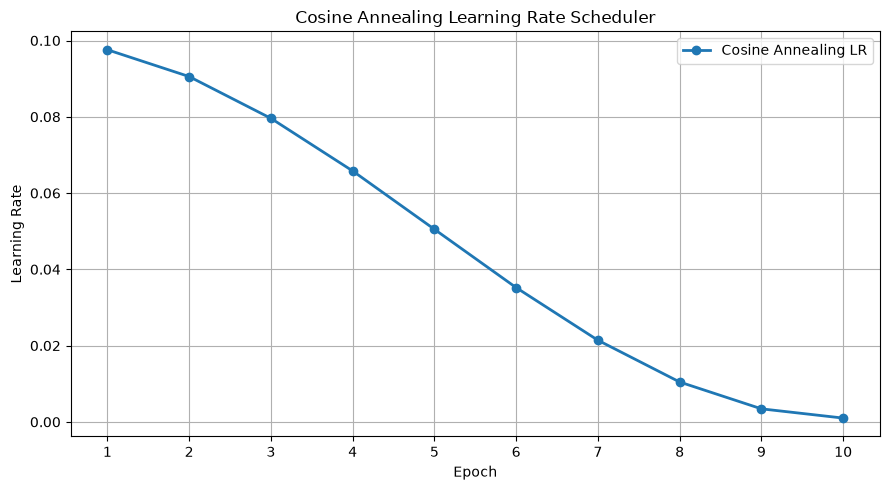

In [6]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Create model
model = nn.Linear(10, 1)

# 2. Define loss function
criterion = nn.MSELoss()

# 3. Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.1
)

# 4. Define Cosine Annealing Scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10,
    eta_min=0.001
)

# 5. Store learning rates and losses
lr_history = []
loss_history = []

# 6. Training loop
epochs = 10

for epoch in range(epochs):

    # Generate sample data
    x = torch.randn(32, 10)
    target = torch.randn(32, 1)

    # Forward propagation
    optimizer.zero_grad()
    output = model(x)
    loss = criterion(output, target)

    # Backpropagation
    loss.backward()

    # Update model weights
    optimizer.step()

    # Update scheduler
    scheduler.step()

    # Record learning rate after scheduler update
    current_lr = optimizer.param_groups[0]['lr']
    lr_history.append(current_lr)
    loss_history.append(loss.item())

    print(
        f"Epoch: {epoch+1:02d} | "
        f"Loss: {loss.item():.4f} | "
        f"LR: {current_lr:.6f}"
    )

# 7. Plot Learning Rate graph
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    lr_history,
    marker='o',
    linewidth=2,
    label='Cosine Annealing LR'
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Cosine Annealing Learning Rate Scheduler")
plt.grid(True)
plt.legend()
plt.xticks(range(1, epochs + 1))

plt.tight_layout()
plt.show()


#### How do you select an optimizer and learning rate for a new task?

When starting a new deep learning project, I select the optimizer and learning rate based on the **task, model architecture, dataset size, batch size, and training stability.**

### Selecting an optimizer

Different optimizers work differently depending on the problem.

| Optimizer | Best use case | Characteristics |
| :--- | :--- | :--- |
| **SGD** | CNN, image classification | Simple, good generalization with proper tuning |
| **SGD + Momentum** | Computer vision | Accelerates convergence |
| **Adam** | General deep learning | Adaptive learning rates |
| **AdamW** | Transformers, LLMs | Adam with decoupled weight decay |
| **RMSprop** | RNNs, non-stationary problems | Adaptive learning rates |

- CNN / Computer Vision → SGD with Momentum or AdamW.
- Transformer / LLM → AdamW.
- General neural network / MLP → Adam.
- Fine-tuning pertained models → AdamW.

## Gradient Checkpointing [PyTorch memory optimization technique]

**Gradient Checkpointing** is a PyTorch memory optimization technique that reduces GPU memory consumption during model training by **trading computation time for memory**.

Normally, during the forward pass, PyTorch stores intermediate activations (tensor values) required for backpropagation. For large models, these activations consume significant GPU VRAM. Gradient checkpointing avoids storing all intermediate activations. Instead, it stores selected activations (checkpoints) and recomputes the missing intermediate activations during the backward pass.

**1. Without Gradient Checkpointing**

Normal training works as follows:

1. **Forward pass:** Calculate outputs and store intermediate activations.
2. **Backward pass:** Reuse stored activations to calculate gradients.
3. **Memory:** Retain many intermediate tensors until backward computation finishes.

![Deep Neural Network: Forward and Backward Propagation](image-11.png)

**Problem:** Large models such as LLMs can require substantial VRAM to store intermediate activations.

**2. With Gradient Checkpointing**

Instead of storing every intermediate activation, PyTorch stores only selected checkpoints. During backward propagation, it recomputes the intermediate activations from those checkpoints when needed.

![Gradient Checkpointing](image-12.png)

The process:

1. Forward pass: Calculate intermediate activations.
2. Store only selected checkpoint activations.
3. Discard certain intermediate activations.
4. Backward pass: Recompute discarded activations.
5. Calculate gradients using recomputed activations.

**3. PyTorch implementation**

PyTorch provides `torch.utils.checkpoint.checkpoint()`.

**Interview takeaway:** Gradient checkpointing reduces GPU memory by discarding selected intermediate activations during the forward pass and recomputing them during backward propagation. It trades additional computation time for reduced VRAM consumption.

**Remember:** Gradient checkpointing does not reduce model parameters. It primarily reduces activation memory, not the memory required to store model weights and optimizer states.


In [1]:

import torch
import gc
from torch.utils.checkpoint import checkpoint

device = "cuda"

# Large input tensor: 2048 x 2048
# FP32 = approximately 16 MB
def create_input():
    return torch.randn(
        2048, 2048,
        device=device,
        requires_grad=True
    )


# Computational block
def compute_block(x):
    for _ in range(4):
        x = torch.sin(x)
        x = x * x
        x = torch.cos(x)

    return x


# Multiple computational blocks
def model(x, use_checkpoint=False):

    for _ in range(8):

        if use_checkpoint:
            x = checkpoint(
                compute_block,
                x,
                use_reentrant=False
            )
        else:
            x = compute_block(x)

    return x


def measure_memory(use_checkpoint):

    gc.collect()
    torch.cuda.empty_cache()

    x = create_input()

    # Synchronize before measurement
    torch.cuda.synchronize()

    torch.cuda.reset_peak_memory_stats()

    # Forward pass
    output = model(x, use_checkpoint)

    # Calculate loss
    loss = output.mean()

    # Backward pass
    loss.backward()

    torch.cuda.synchronize()

    # Measure peak GPU memory
    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    print(
        f"Checkpoint: {use_checkpoint}, "
        f"Peak Memory: {peak_memory:.2f} MB"
    )

    del x, output, loss
    gc.collect()
    torch.cuda.empty_cache()

    return peak_memory


# Run comparison
print("Without Gradient Checkpointing")
memory_without = measure_memory(False)

print("\nWith Gradient Checkpointing")
memory_with = measure_memory(True)

print("\nMemory Comparison")

print(f"Without Checkpoint: {memory_without:.2f} MB")
print(f"With Checkpoint:    {memory_with:.2f} MB")

print(
    f"Memory Saved: "
    f"{memory_without - memory_with:.2f} MB"
)

print(
    f"Memory Reduction: "
    f"{(memory_without - memory_with) / memory_without * 100:.2f}%"
)


Without Gradient Checkpointing
Checkpoint: False, Peak Memory: 1616.00 MB

With Gradient Checkpointing
Checkpoint: True, Peak Memory: 384.00 MB

Memory Comparison
Without Checkpoint: 1616.00 MB
With Checkpoint:    384.00 MB
Memory Saved: 1232.00 MB
Memory Reduction: 76.24%


#### Q. Checkpointing save selected node. Possible loss information's. Explain Issue with Checkpointing.

Gradient checkpointing saves selected activation tensors (checkpoints) during the forward pass and discards certain intermediate activations. During the backward pass, PyTorch recomputes the discarded activations from the saved checkpoints.

Does this cause loss of information? Normally, no. Gradient checkpointing is designed to preserve the mathematical gradients and training results, subject to normal floating-point numerical differences. However, there are some important issues.

**1. Major issues with Gradient Checkpointing**

**1. Additional computation time**

PyTorch must recompute intermediate activations during backward propagation. This increases computational workload and can slow down training.

**2. Random operations (Dropout)**

Suppose your model uses `Dropout()`. During the forward pass, some neurons are randomly disabled. During recomputation, PyTorch needs to reproduce the same dropout behavior to maintain correct gradients. PyTorch checkpointing normally preserves RNG state by default, but custom randomness or different device behavior can cause inconsistencies.

**3. Batch Normalization**

Batch Normalization maintains running statistics such as `running_mean` and `running_var`. If checkpointed operations execute again during backward propagation, these running statistics can be updated more than once. This can affect training behavior.

**4. Side effects during recomputation**

Suppose your forward function updates a global counter, writes to a file, or modifies shared memory. Checkpointing may execute that function again during backward propagation, causing unintended duplicate side effects.

**5. Incorrect gradients with changing inputs or state**

If model parameters, global variables, or inputs change between the original forward pass and recomputation, the recomputed activations may differ. This can produce incorrect gradients.

**3. Summary of issues**

| Issue | Possible impact |
| :--- | :--- |
| Recomputation | Slower training |
| Dropout randomness | Different activations if RNG state is not preserved |
| BatchNorm | Running statistics may update multiple times |
| Global variables | Duplicate side effects |
| Modified parameters | Incorrect recomputation |
| Complex control flow | Recomputed execution may differ |

**4. How to use checkpointing safely**

* Use `use_reentrant=False` (recommended for modern PyTorch).
* Keep checkpointed functions free of unnecessary side effects.
* Preserve RNG state when using Dropout.
* Be careful with BatchNorm and other stateful layers.
* Avoid modifying model parameters during forward execution.

**Interview takeaway:** Gradient checkpointing does not normally lose activation information or compromise gradient correctness. It discards selected intermediate activations and recomputes them during backward propagation. However, recomputation overhead, random operations, stateful layers, and side effects must be handled carefully.
